---
embed-resources: True
format:
    html:
        page-layout: full
        fontsize: 18px

title: 'Parte I | Optimización primal de la red'
author: 'Lorenzo Marquesini'
warning: False
toc: False
---

## Pregunta y alcance

La gerencia logística de Red Federal de Insumos Esenciales decide cuánto despachar cada semana desde tres centros (Norte, Centro, Sur) hacia cinco zonas (Capital, Oeste, Este, Costa, Interior). La pregunta de esta parte es:

> **¿Qué plan cubre la demanda nominal con el menor costo total, permitiendo faltante sólo cuando la red no alcanza y haciéndolo visible mediante una penalización?**

El notebook valida los datos, formula y resuelve el modelo lineal con OR-Tools (GLOP), verifica la solución de dos maneras independientes, resuelve los escenarios S1, S2 y S3 y exporta las dos políticas fijas que evalúa la Parte II: el plan nominal y el plan de resguardo.

**Unidades.** El flujo se mide en *unidades logísticas equivalentes por semana*, un agregado divisible: por eso las variables son continuas. Los costos son **puntos de costo logístico** (flete, manipulación y seguro), no pesos ni dólares. La penalización por faltante es un costo social explícito, no un precio de venta.

**Procedencia.** `destinations.csv` y `routes.csv` son los datos del caso. La oferta de `origins.csv` es una **reconstrucción** porque el archivo original no estaba disponible (ver `README.md` y `model_card/part1_fma.md`). Todos los costos y faltantes de esta parte dependen de esa oferta.

**Ejecución.** Desde `notebooks/` o desde la raíz del repositorio; el notebook localiza la raíz y usa rutas relativas a ella. La lógica reutilizable vive en `src/` y se muestra en el notebook donde se usa.

**Datasets de esta celda:** `destinations.csv`, `origins.csv`, `routes.csv`.

- `destinations.csv` — zonas. `destination` (Capital, Oeste, Este, Costa, Interior); `nominal_demand` 35–50; `shortage_penalty` 60–80; `initial_inventory` 5–8; `storage_capacity` 48–65; `holding_cost` 0.30–0.40; `waste_cost` 0.60–0.80.
- `origins.csv` — centros. `origin` (Norte, Centro, Sur); `supply` 60–95 unidades/semana (oferta reconstruida).
- `routes.csv` — corredores. `route_id` (15 ids, `N-CAP` a `S-INT`); `origin` (Norte, Centro, Sur); `destination` (las cinco zonas); `unit_cost` 3–9; `capacity` 18–42.


Al cargar, `cargar_datos` verifica columnas obligatorias, ausencia de faltantes, valores numéricos finitos y no negativos, claves únicas, que las 15 rutas esperadas existan y que cada ruta apunte a un centro y una zona declarados. Ningún valor faltante se completa en silencio: si algo no cumple, la ejecución se detiene.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "datos.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display

from src import graficos as g
from src.datos import DATA_DIR, OUTPUTS_DIR, cargar_datos, sha256
from src.transporte import (
    TOL, SolverError, certificado, comparar_flujos, exportar_politica, resolver, techo, verificar,
)

origins, destinations, routes = cargar_datos(DATA_DIR)
print(f"Datos validados: {len(origins)} centros, {len(destinations)} zonas, {len(routes)} rutas")

Datos validados: 3 centros, 5 zonas, 15 rutas


## Introducción a los datos

**destinations.csv** — una fila por zona de entrega.

- `destination`: zona. Capital, Oeste, Este, Costa, Interior.
- `nominal_demand`: demanda de la semana típica, unidades logísticas/semana. 35–50.
- `shortage_penalty`: puntos por unidad no atendida. 60–80.
- `initial_inventory`: existencias al inicio del horizonte, unidades. 5–8.
- `storage_capacity`: tope almacenable al cierre de la semana, unidades. 48–65.
- `holding_cost`: puntos por unidad guardada y semana. 0.30–0.40.
- `waste_cost`: puntos por unidad descartada. 0.60–0.80.


**origins.csv** — una fila por centro de consolidación.

- `origin`: centro. Norte, Centro, Sur.
- `supply`: máximo despachable en la semana nominal, unidades logísticas/semana. 60–95. Oferta reconstruida: no vino en los datos de la cátedra.


**routes.csv** — una fila por corredor habilitado.

- `route_id`: identificador del corredor. 15 valores, de `N-CAP` a `S-INT`.
- `origin`: centro de salida. Norte, Centro, Sur.
- `destination`: zona de llegada. Capital, Oeste, Este, Costa, Interior.
- `unit_cost`: puntos logísticos por unidad despachada. 3–9.
- `capacity`: máximo de la ruta antes del estado aleatorio, unidades/semana. 18–42.


## Exploración de datos

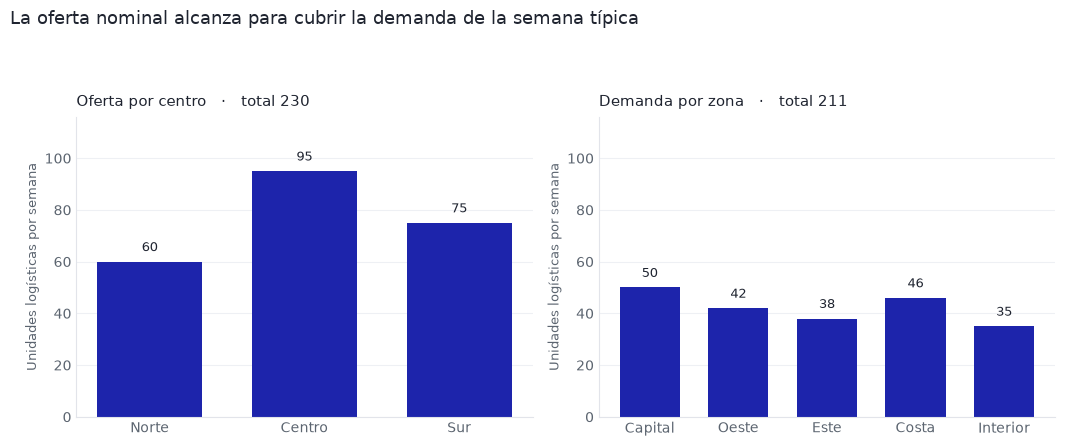

In [2]:
PRIMARY, INK, MUTED = g.PRIMARY, g.INK, g.MUTED

supply_total = origins["supply"].sum()
demand_total = destinations["nominal_demand"].sum()
ymax = max(origins["supply"].max(), destinations["nominal_demand"].max()) * 1.22

fig, axes = plt.subplots(1, 2, figsize=(10.6, 4.5))
fig.suptitle(
    "La oferta nominal alcanza para cubrir la demanda de la semana típica",
    fontsize=13,
    color=INK,
    x=0.0,
    ha="left",
)

panels = [
    (axes[0], origins["origin"], origins["supply"], f"Oferta por centro   ·   total {supply_total:.0f}"),
    (axes[1], destinations["destination"], destinations["nominal_demand"], f"Demanda por zona   ·   total {demand_total:.0f}"),
]
for ax, labels, values, title in panels:
    positions = range(len(labels))
    bars = ax.bar(positions, values, color=PRIMARY, width=0.68, zorder=2)
    ax.set_title(title, loc="left", fontsize=11, color=INK, pad=8)
    ax.set_ylabel("Unidades logísticas por semana", color=MUTED, fontsize=9)
    ax.set_xticks(list(positions), list(labels))
    ax.set_ylim(0, ymax)
    ax.tick_params(axis="both", colors=MUTED, length=0, labelsize=10)
    ax.yaxis.grid(True, color="#EEF0F4", zorder=0)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#E2E4EA")
    ax.spines["bottom"].set_color("#E2E4EA")
    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + ymax * 0.025,
            f"{value:.0f}",
            ha="center",
            va="bottom",
            fontsize=9,
            color=INK,
        )

fig.tight_layout(rect=(0, 0, 1, 0.90))
plt.show()

## Matriz de transporte

Cada celda es el costo unitario de la ruta, en puntos logísticos por unidad. *Oferta* es lo máximo que puede despachar cada centro y *Demanda* lo que necesita cada zona, ambas en unidades por semana.

In [3]:
centers = origins["origin"].tolist()
zones = destinations["destination"].tolist()
cost = routes.pivot(index="origin", columns="destination", values="unit_cost").loc[centers, zones]
supply = origins.set_index("origin")["supply"]
demand = destinations.set_index("destination")["nominal_demand"]

HTML(g.tabla_doble_entrada(
    centers, zones, lambda i, j: f"{cost.loc[i, j]:.0f}",
    extra_col=("Oferta", lambda i: f"{supply.loc[i]:.0f}"),
    extra_fila=("Demanda", lambda j: f"{demand.loc[j]:.0f}"),
))

HaciaDesde,Capital,Oeste,Este,Costa,Interior,Oferta
Norte,4,6,5,9,7,60
Centro,5,3,4,6,5,95
Sur,8,6,5,3,4,75
Demanda,50,42,38,46,35,


## Red de transporte

Cada flecha es una ruta habilitada. El número sobre la flecha es el costo unitario, en puntos por unidad. A la izquierda está la oferta del centro y a la derecha la demanda de la zona.

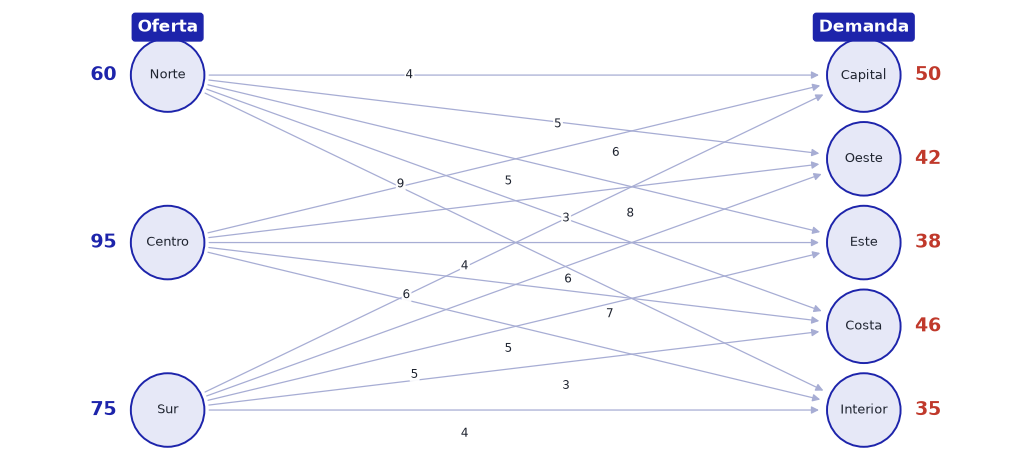

In [4]:
import math
from matplotlib.patches import Circle, FancyArrowPatch

BLUE, RED, INK = g.BLUE, g.RED, g.INK
FILL = "#E6E8F7"
EDGE = "#A7ADD4"

centers = origins["origin"].tolist()
zones = destinations["destination"].tolist()
supply = origins.set_index("origin")["supply"]
demand = destinations.set_index("destination")["nominal_demand"]
cost = routes.set_index(["origin", "destination"])["unit_cost"]

def column_ys(n, top=5.55, bottom=0.45):
    step = (top - bottom) / (n - 1)
    return [top - i * step for i in range(n)]

pos = {name: (1.7, y) for name, y in zip(centers, column_ys(len(centers)))}
pos.update({name: (12.3, y) for name, y in zip(zones, column_ys(len(zones)))})
radius = 0.56

fig, ax = plt.subplots(figsize=(14.6, 5.8))
ax.set_xlim(-0.7, 14.4)
ax.set_ylim(-0.25, 6.55)
ax.set_aspect("equal")
ax.axis("off")

def badge(x, y, text):
    ax.text(
        x, y, text, ha="center", va="center", fontsize=12, color="white", fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.32,rounding_size=0.18", facecolor=BLUE, edgecolor=BLUE),
        zorder=6,
    )

badge(1.7, 6.28, "Oferta")
badge(12.3, 6.28, "Demanda")

for name, (x, y) in pos.items():
    ax.add_patch(Circle((x, y), radius, facecolor=FILL, edgecolor=BLUE, lw=1.4, zorder=3))
    ax.text(x, y, name, ha="center", va="center", fontsize=9, color=INK, zorder=4)

for name in centers:
    x, y = pos[name]
    ax.text(x - radius - 0.22, y, f"{supply.loc[name]:.0f}", ha="right", va="center", fontsize=14, color=BLUE, fontweight="bold", zorder=4)
for name in zones:
    x, y = pos[name]
    ax.text(x + radius + 0.22, y, f"{demand.loc[name]:.0f}", ha="left", va="center", fontsize=14, color=RED, fontweight="bold", zorder=4)

def arrow_ends(origin, zone):
    x1, y1 = pos[origin]
    x2, y2 = pos[zone]
    dx, dy = x2 - x1, y2 - y1
    dist = math.hypot(dx, dy)
    ux, uy = dx / dist, dy / dist
    start = (x1 + ux * (radius + 0.03), y1 + uy * (radius + 0.03))
    end = (x2 - ux * (radius + 0.08), y2 - uy * (radius + 0.08))
    return start, end, (-uy, ux)

placed = []

def nearest(point):
    if not placed:
        return 99
    return min(math.hypot(point[0] - other[0], point[1] - other[1]) for other in placed)

for origin in centers:
    for zone in zones:
        start, end, (nx, ny) = arrow_ends(origin, zone)
        ax.add_patch(FancyArrowPatch(
            start, end, arrowstyle="-|>", mutation_scale=11, lw=0.9, color=EDGE, zorder=2,
        ))
        best, best_score = None, -1
        for t in (0.33, 0.42, 0.50, 0.58, 0.67):
            for offset in (0.0, 0.2, -0.2, 0.36, -0.36):
                x = start[0] + t * (end[0] - start[0]) + offset * nx
                y = start[1] + t * (end[1] - start[1]) + offset * ny
                if not (3.0 < x < 11.0 and 0.05 < y < 6.05):
                    continue
                score = nearest((x, y)) - 0.04 * abs(offset)
                if score > best_score:
                    best_score, best = score, (x, y)
        placed.append(best)
        ax.text(
            best[0], best[1], f"{cost.loc[(origin, zone)]:.0f}",
            ha="center", va="center", fontsize=8.5, color=INK, zorder=5,
            bbox=dict(boxstyle="round,pad=0.08", facecolor="white", edgecolor="none", alpha=0.94),
        )

plt.show()

## Variables de decisión

Qué puede decidir la gerencia en la semana nominal: cuánto enviar por cada ruta y cuánto faltante dejar explícito en cada zona.


In [5]:
from src.graficos import block, line, s, x

centers = origins["origin"].tolist()
zones = destinations["destination"].tolist()
routes_ix = routes.set_index(["origin", "destination"]).sort_index()

parts = []
for origin in centers:
    for zone in zones:
        parts.append(line(
            f"{x(origin, zone)} = unidades enviadas de {origin} a {zone}",
        ))
    parts.append("<div style='height:8px'></div>")
for zone in zones:
    parts.append(line(f"{s(zone)} = unidades no atendidas en {zone}"))

parts.append("<div style='height:14px'></div>")
parts.append(line(f"{x('i', 'j')} = flujo planificado del centro i a la zona j, en unidades logísticas por semana"))
parts.append(line("i = " + ", ".join(centers)))
parts.append(line("j = " + ", ".join(zones)))
parts.append(line(f"{s('j')} = faltante de la zona j, en unidades logísticas por semana"))
HTML(block(parts))

## Función objetivo

Se minimiza el costo de los envíos más la penalización por cada unidad no atendida, ambos en puntos logísticos por semana.

In [6]:
from src.graficos import block, line, s, x

centers = origins["origin"].tolist()
zones = destinations["destination"].tolist()
cost = routes.set_index(["origin", "destination"])["unit_cost"]
penalty = destinations.set_index("destination")["shortage_penalty"]

parts = [line("<b>Minimizar</b>")]
for origin in centers:
    terms = " + ".join(f"{cost.loc[(origin, zone)]:.0f} {x(origin, zone)}" for zone in zones)
    parts.append(line(terms))
shortage = " + ".join(f"{penalty.loc[zone]:.0f} {s(zone)}" for zone in zones)
parts.append(line("+ " + shortage))
HTML(block(parts))

## Sujeto a

La oferta de cada centro, la capacidad de cada ruta y la demanda de cada zona. El faltante entra en el balance para que la demanda no cubierta quede visible.


In [7]:
from src.graficos import block, line, s, x

centers = origins["origin"].tolist()
zones = destinations["destination"].tolist()
supply = origins.set_index("origin")["supply"]
demand = destinations.set_index("destination")["nominal_demand"]
capacity = routes.set_index(["origin", "destination"])["capacity"]

parts = [line("<b>Oferta de cada centro</b>")]
for origin in centers:
    terms = " + ".join(x(origin, zone) for zone in zones)
    parts.append(line(f"{terms} &le; {supply.loc[origin]:.0f}", f"(oferta de {origin})"))

parts.append("<div style='height:12px'></div>")
parts.append(line("<b>Capacidad de cada ruta</b>"))
for origin in centers:
    for zone in zones:
        parts.append(line(
            f"{x(origin, zone)} &le; {capacity.loc[(origin, zone)]:.0f}",
            f"(capacidad {origin}–{zone})",
        ))

parts.append("<div style='height:12px'></div>")
parts.append(line("<b>Demanda de cada zona</b>"))
for zone in zones:
    terms = " + ".join(x(origin, zone) for origin in centers)
    parts.append(line(f"{terms} + {s(zone)} = {demand.loc[zone]:.0f}", f"(demanda de {zone})"))

parts.append("<div style='height:12px'></div>")
parts.append(line("<b>No negatividad</b>"))
all_x = ", ".join(x(origin, zone) for origin in centers for zone in zones)
all_s = ", ".join(s(zone) for zone in zones)
parts.append(line(f"{all_x} &ge; 0"))
parts.append(line(f"{all_s} &ge; 0"))
HTML(block(parts))

## Ficha del modelo

La ficha completa, con columnas fuente y supuestos, está en `model_card/part1_fma.md`.

**Decisor.** Gerencia logística de Red Federal de Insumos Esenciales.

**Horizonte.** Una semana operativa típica.

**Conjuntos.** Centros $I=\{\text{Norte}, \text{Centro}, \text{Sur}\}$. Zonas $J=\{\text{Capital}, \text{Oeste}, \text{Este}, \text{Costa}, \text{Interior}\}$. Rutas habilitadas $E \subseteq I \times J$: las 15 de `routes.csv`.

**Datos y unidades.**

- $a_i$: `origins.supply`, unidades logísticas por semana. Oferta reconstruida: Norte 60, Centro 95, Sur 75.
- $d_j$: `destinations.nominal_demand`, unidades por semana.
- $u_{ij}$: `routes.capacity`, unidades por semana.
- $c_{ij}$: `routes.unit_cost`, puntos logísticos por unidad.
- $p_j$: `destinations.shortage_penalty`, puntos por unidad no atendida. No es un precio de venta.

**Variables.** $x_{ij}\ge 0$, flujo planificado por la ruta $(i,j)$. $s_j\ge 0$, demanda no atendida en la zona $j$. Ambas continuas y en unidades por semana.

**Modelo.**

$$
\begin{aligned}
\min_{x,s}\quad & \sum_{(i,j)\in E} c_{ij}\,x_{ij} + \sum_{j\in J} p_j\, s_j \\
\text{s.a.}\quad & \sum_{j:(i,j)\in E} x_{ij} \le a_i && \forall i\in I \\
& x_{ij} \le u_{ij} && \forall (i,j)\in E \\
& \sum_{i:(i,j)\in E} x_{ij} + s_j = d_j && \forall j\in J \\
& x_{ij}\ge 0,\quad s_j \ge 0 .
\end{aligned}
$$

**Supuestos.** El faltante se ve y se penaliza; no desaparece de la cuenta. No hay pedidos pendientes dentro de la semana. No se exige despacho en pallets enteros; si fuera obligatorio, haría falta un modelo entero, fuera del alcance.

**Tres pruebas a mano.** Un solo corredor Norte–Capital, costo 4 y penalización 80.

1. Factible: oferta 10, capacidad 10, demanda 6. Debe enviar 6, sin faltante, a costo $4\cdot 6 = 24$.
2. Infactible: capacidad 3, demanda 6 y **sin** variable de faltante. Ningún $x \le 3$ cumple $x = 6$. Con faltante, el modelo envía 3 y declara 3 faltantes: $4\cdot 3 + 80\cdot 3 = 252$.
3. Borde: oferta, capacidad y demanda iguales a 6. El envío llena las dos cotas y el faltante queda en cero.

Los tres casos se resuelven con la misma función `resolver` que el caso real.

In [8]:
def caso_mini(oferta, capacidad, demanda, costo=4.0, penalizacion=80.0, con_faltante=True):
    rutas = pd.DataFrame({
        "route_id": ["N-CAP"], "origin": ["Norte"], "destination": ["Capital"],
        "unit_cost": [costo], "capacity": [capacidad],
    })
    zonas = pd.DataFrame({"destination": ["Capital"], "shortage_penalty": [penalizacion]})
    return resolver(
        rutas, zonas, pd.Series({"Capital": demanda}), pd.Series({"Norte": oferta}),
        pd.Series({"N-CAP": capacidad}), "caso mini", permitir_faltante=con_faltante,
    )

def fila_caso(nombre, esperado, **kwargs):
    try:
        sol = caso_mini(**kwargs)
    except SolverError as error:
        return {"caso": nombre, "estado": error.estado, "x": np.nan, "s": np.nan, "costo": np.nan, "esperado": esperado}
    return {
        "caso": nombre, "estado": sol.estado, "x": sol.flujos["flujo"].iloc[0],
        "s": sol.faltantes["faltante"].iloc[0], "costo": sol.objetivo, "esperado": esperado,
    }

casos = pd.DataFrame([
    fila_caso("1. Factible", "x=6, s=0, costo 24", oferta=10, capacidad=10, demanda=6),
    fila_caso("2. Sin faltante", "INFEASIBLE", oferta=10, capacidad=3, demanda=6, con_faltante=False),
    fila_caso("2b. Con faltante", "x=3, s=3, costo 252", oferta=10, capacidad=3, demanda=6),
    fila_caso("3. Borde", "x=6, s=0, costo 24", oferta=6, capacidad=6, demanda=6),
])
assert casos.loc[1, "estado"] == "INFEASIBLE"
assert np.allclose(casos.loc[[0, 2, 3], ["x", "s", "costo"]].to_numpy(dtype=float),
                   [[6, 0, 24], [3, 3, 252], [6, 0, 24]], rtol=0, atol=TOL)
casos

,caso,estado,x,s,costo,esperado
0,1. Factible,OPTIMAL,6.0,0.0,24.0,"x=6, s=0, costo 24"
1,2. Sin faltante,INFEASIBLE,NaN,NaN,NaN,INFEASIBLE
2,2b. Con faltante,OPTIMAL,3.0,3.0,252.0,"x=3, s=3, costo 252"
3,3. Borde,OPTIMAL,6.0,0.0,24.0,"x=6, s=0, costo 24"


## Planteo con OR-Tools

La función `resolver` de `src/transporte.py` es la única implementación del modelo: la usan el caso nominal, los tres escenarios, el plan de resguardo, los casos mini y las pruebas automáticas. Recibe demanda, oferta y capacidades como argumentos —no lee variables globales—, rechaza datos no finitos o negativos, comprueba que GLOP se haya creado y se detiene con `SolverError` si el estado de terminación no es `OPTIMAL`. Crea una variable con nombre por ruta y por faltante y una restricción con nombre por centro, ruta y zona.

In [9]:
g.mostrar_codigo(resolver)

```python
def resolver(
    routes: pd.DataFrame,
    destinations: pd.DataFrame,
    demanda: pd.Series,
    oferta: pd.Series,
    capacidad: pd.Series,
    nombre: str = "",
    permitir_faltante: bool = True,
) -> SolucionTransporte:
    """Construye y resuelve el LP con GLOP.

    `demanda` se indexa por zona, `oferta` por centro y `capacidad` por route_id.
    Con `permitir_faltante=False` las variables s_j quedan fijas en cero, lo que sirve
    para mostrar que sin faltante explícito el modelo puede ser infactible.
    """
    demanda = _serie_valida(demanda, destinations["destination"], "demanda")
    capacidad = _serie_valida(capacidad, routes["route_id"], "capacidad")
    oferta = _serie_valida(oferta, oferta.index, "oferta")
    if set(routes["origin"]) - set(oferta.index):
        raise ValueError("oferta: hay rutas que salen de un centro sin oferta declarada")
    for columna in ("unit_cost",):
        if not np.isfinite(routes[columna].to_numpy(dtype=float)).all() or (routes[columna] < 0).any():
            raise ValueError(f"routes.{columna}: hay valores no finitos o negativos")
    penalizacion = destinations.set_index("destination")["shortage_penalty"].astype(float)
    if not np.isfinite(penalizacion.to_numpy()).all() or (penalizacion < 0).any():
        raise ValueError("shortage_penalty: hay valores no finitos o negativos")

    modelo = pywraplp.Solver.CreateSolver("GLOP")
    if modelo is None:
        raise SolverError("NO_CREADO", nombre)
    x = {
        row.route_id: modelo.NumVar(0, modelo.infinity(), f"x_{row.route_id}")
        for row in routes.itertuples(index=False)
    }
    tope_faltante = modelo.infinity() if permitir_faltante else 0.0
    s = {zone: modelo.NumVar(0, tope_faltante, f"s_{zone}") for zone in destinations["destination"]}

    for origin in oferta.index:
        salidas = routes.loc[routes["origin"] == origin, "route_id"]
        modelo.Add(sum(x[rid] for rid in salidas) <= float(oferta.loc[origin]), f"oferta_{origin}")
    for row in routes.itertuples(index=False):
        modelo.Add(x[row.route_id] <= float(capacidad.loc[row.route_id]), f"capacidad_{row.route_id}")
    for zone in destinations["destination"]:
        entradas = routes.loc[routes["destination"] == zone, "route_id"]
        modelo.Add(sum(x[rid] for rid in entradas) + s[zone] == float(demanda.loc[zone]), f"demanda_{zone}")
    modelo.Minimize(
        sum(row.unit_cost * x[row.route_id] for row in routes.itertuples(index=False))
        + sum(float(penalizacion.loc[zone]) * s[zone] for zone in s)
    )

    estado = ESTADOS_SOLVER.get(modelo.Solve(), "DESCONOCIDO")
    if estado != "OPTIMAL":
        raise SolverError(estado, nombre)

    flujos = routes[["route_id", "origin", "destination", "unit_cost"]].copy()
    flujos["capacity"] = flujos["route_id"].map(capacidad).astype(float)
    flujos["flujo"] = [x[rid].solution_value() for rid in flujos["route_id"]]
    faltantes = destinations[["destination", "shortage_penalty"]].copy()
    faltantes["demanda"] = faltantes["destination"].map(demanda).astype(float)
    faltantes["faltante"] = [s[zone].solution_value() for zone in faltantes["destination"]]
    return SolucionTransporte(nombre, estado, modelo.Objective().Value(), flujos, faltantes, modelo)
```

In [10]:
demanda_nominal = destinations.set_index("destination")["nominal_demand"]
oferta_nominal = origins.set_index("origin")["supply"]
capacidad_nominal = routes.set_index("route_id")["capacity"]

nominal = resolver(routes, destinations, demanda_nominal, oferta_nominal, capacidad_nominal, "Nominal")
costo_nominal = nominal.objetivo
faltante_nominal = float(nominal.faltantes["faltante"].sum())

print("Estado:", nominal.estado)
print(f"Costo mínimo = {costo_nominal:.2f} puntos logísticos por semana")
print(f"Faltante total = {faltante_nominal:.2f} unidades")
display(nominal.flujos.assign(aporte=nominal.flujos["flujo"] * nominal.flujos["unit_cost"]).round(4))
display(nominal.faltantes.round(4))

Estado: OPTIMAL
Costo mínimo = 818.00 puntos logísticos por semana
Faltante total = 0.00 unidades


,route_id,origin,destination,unit_cost,capacity,flujo,aporte
0,N-CAP,Norte,Capital,4.0,42.0,42.0,168.0
1,N-OES,Norte,Oeste,6.0,28.0,0.0,0.0
2,N-EST,Norte,Este,5.0,30.0,4.0,20.0
3,N-COS,Norte,Costa,9.0,18.0,0.0,0.0
4,N-INT,Norte,Interior,7.0,26.0,0.0,0.0
5,C-CAP,Centro,Capital,5.0,35.0,8.0,40.0
6,C-OES,Centro,Oeste,3.0,35.0,35.0,105.0
7,C-EST,Centro,Este,4.0,34.0,34.0,136.0
8,C-COS,Centro,Costa,6.0,32.0,8.0,48.0
9,C-INT,Centro,Interior,5.0,28.0,5.0,25.0


,destination,shortage_penalty,demanda,faltante
0,Capital,80.0,50.0,0.0
1,Oeste,70.0,42.0,0.0
2,Este,65.0,38.0,0.0
3,Costa,75.0,46.0,0.0
4,Interior,60.0,35.0,0.0


**Lectura.** El plan nominal cubre las 211 unidades de demanda sin faltante, con un costo de 818 puntos. Sur despacha toda su oferta (75) por sus rutas baratas a Costa e Interior; Norte deja 14 unidades sin usar y Centro 5. Cinco rutas quedan llenas (N-CAP, C-OES, C-EST, S-COS y S-INT): son los corredores baratos que limitan la mejora del costo.

## Certificado de optimalidad

Este control usa la información dual que reporta GLOP; por eso es complementario a la verificación independiente de la sección siguiente, que no lee nada del solver salvo los flujos.

Con la convención de OR-Tools para minimizar, el dual $y$ de una restricción es la derivada del objetivo respecto de su lado derecho, y el costo reducido de una variable es $\bar c = c - A^\top y$. El plan es óptimo si:

1. **Factibilidad dual (signos).** Una restricción $\le$ tiene $y \le 0$: aumentar una oferta o una capacidad no puede encarecer el plan. Las igualdades de demanda tienen dual libre.
2. **Holgura complementaria.** Si una restricción tiene holgura, su dual es cero. Si una variable está en cero (cota inferior), su costo reducido es $\ge 0$; si está entre cotas, es cero.
3. **Brecha nula.** El objetivo dual $\sum y\cdot b + \sum \bar c \cdot (\text{cota activa})$ coincide con el primal.

`VerifySolution` de GLOP se reporta como control adicional, no como sustituto.

In [11]:
cert = certificado(nominal)
resumen_cert = cert["resumen"]
assert resumen_cert["certificado_ok"], resumen_cert

print(f"Objetivo primal          = {resumen_cert['objetivo_primal']:.4f}")
print(f"Objetivo dual            = {resumen_cert['objetivo_dual']:.4f}")
print(f"Brecha                   = {resumen_cert['brecha']:.2e}")
print(f"Signos duales            : {'cumple' if resumen_cert['signos_duales_ok'] else 'NO cumple'}")
print(f"Holgura complementaria   : {'cumple' if resumen_cert['holgura_complementaria_ok'] else 'NO cumple'}")
print(f"VerifySolution de GLOP   : {resumen_cert['verify_solution_glop']}")
print(f"Iteraciones              = {resumen_cert['iteraciones']}")
display(cert["variables"].round(4))
display(cert["restricciones"].round(4))

Objetivo primal          = 818.0000
Objetivo dual            = 818.0000
Brecha                   = 0.00e+00
Signos duales            : cumple
Holgura complementaria   : cumple
VerifySolution de GLOP   : True
Iteraciones              = 11


,variable,valor,costo_reducido,holgura_complementaria,base
0,x_N-CAP,42.0,0.0,True,básica
1,x_N-OES,0.0,0.0,True,cota inferior
2,x_N-EST,4.0,0.0,True,básica
3,x_N-COS,0.0,3.0,True,cota inferior
4,x_N-INT,0.0,2.0,True,cota inferior
5,x_C-CAP,8.0,0.0,True,básica
6,x_C-OES,35.0,0.0,True,básica
7,x_C-EST,34.0,0.0,True,básica
8,x_C-COS,8.0,0.0,True,básica
9,x_C-INT,5.0,0.0,True,básica


,restriccion,tipo,dual,holgura,signo_dual_ok,holgura_complementaria,base
0,oferta_Norte,<=,0.0,14.0,True,True,básica
1,oferta_Centro,<=,0.0,5.0,True,True,básica
2,oferta_Sur,<=,0.0,-0.0,True,True,cota superior
3,capacidad_N-CAP,<=,-1.0,0.0,True,True,cota superior
4,capacidad_N-OES,<=,0.0,28.0,True,True,básica
5,capacidad_N-EST,<=,0.0,26.0,True,True,básica
6,capacidad_N-COS,<=,0.0,18.0,True,True,básica
7,capacidad_N-INT,<=,0.0,26.0,True,True,básica
8,capacidad_C-CAP,<=,0.0,27.0,True,True,básica
9,capacidad_C-OES,<=,-3.0,0.0,True,True,cota superior


**Lectura.** Los duales negativos marcan los recursos que, de ampliarse, abaratarían el plan: una unidad más de capacidad en C-OES o S-COS ahorraría 3 puntos, y una en N-CAP, C-EST o S-INT, 1 punto. Son valores **marginales y locales** del programa nominal: valen para cambios chicos alrededor de este vértice y no dicen cuánto mejoraría el servicio bajo incertidumbre. Los duales de demanda (entre 5 y 6) son el costo marginal de atender una unidad más en cada zona, muy por debajo de su penalización. La oferta de Sur está agotada pero su dual es 0: el plan es degenerado y ese recurso no tiene valor marginal en este vértice. Además, $x_{N\text{-}OES}$ está en cero con costo reducido 0: existen **óptimos alternativos** con el mismo costo de 818 (por ejemplo, mover una unidad de Sur–Oeste a Norte–Oeste y una de Norte–Este a Sur–Este). Por eso las pruebas comparan valor objetivo y factibilidad, no la igualdad de cada flujo.

## Verificación independiente

La función `verificar` toma de la solución sólo los flujos $x_{ij}$ y los faltantes $s_j$. Costos, penalizaciones, ofertas, capacidades y demandas salen de los datos del escenario. Con eso recalcula el costo de transporte, la penalización y el objetivo, y lo compara con el valor que informa el solver; recalcula también el uso y la holgura de cada centro, la holgura de cada ruta, lo recibido por cada zona, el balance $\sum_i x_{ij}+s_j-d_j$ y la no negatividad. La tolerancia declarada es $10^{-7}$. Si un control falla, la ejecución se detiene.

In [12]:
g.mostrar_codigo(verificar)

```python
def verificar(
    solucion: SolucionTransporte,
    routes: pd.DataFrame,
    destinations: pd.DataFrame,
    demanda: pd.Series,
    oferta: pd.Series,
    capacidad: pd.Series,
    tol: float = TOL,
) -> dict:
    """Recalcula objetivo, balances y cotas desde los flujos y los datos del escenario.

    Sólo usa de la solución las columnas `flujo` y `faltante`: costos, capacidades,
    ofertas y demandas salen de los datos. Falla con AssertionError si algún control no pasa.
    """
    flujo = solucion.flujos.set_index("route_id")["flujo"].astype(float)
    faltante = solucion.faltantes.set_index("destination")["faltante"].astype(float)
    assert list(flujo.index) == list(routes["route_id"]), "La solución no tiene exactamente una fila por ruta"
    assert list(faltante.index) == list(destinations["destination"]), "La solución no tiene una fila por zona"
    assert np.isfinite(flujo.to_numpy()).all() and np.isfinite(faltante.to_numpy()).all(), "Hay valores no finitos"

    r = routes.set_index("route_id")
    z = destinations.set_index("destination")
    transporte = float((flujo * r["unit_cost"]).sum())
    penalizacion = float((faltante * z["shortage_penalty"]).sum())
    objetivo = transporte + penalizacion

    uso = flujo.groupby(r["origin"]).sum()
    centros = pd.DataFrame({"oferta": oferta.astype(float), "uso": uso.reindex(oferta.index).fillna(0.0)})
    centros["holgura"] = centros["oferta"] - centros["uso"]

    rutas = pd.DataFrame({
        "flujo": flujo,
        "capacidad": capacidad.reindex(flujo.index).astype(float),
    })
    rutas["holgura"] = rutas["capacidad"] - rutas["flujo"]

    recibido = flujo.groupby(r["destination"]).sum()
    zonas = pd.DataFrame({
        "demanda": demanda.reindex(z.index).astype(float),
        "recibido": recibido.reindex(z.index).fillna(0.0),
        "faltante": faltante,
    })
    zonas["residuo"] = zonas["recibido"] + zonas["faltante"] - zonas["demanda"]

    controles = pd.DataFrame([
        ("Objetivo recalculado = objetivo del solver", abs(objetivo - solucion.objetivo)),
        ("Balance por zona |recibido + faltante - demanda|", float(zonas["residuo"].abs().max())),
        ("Exceso sobre la oferta de un centro", max(0.0, float(-centros["holgura"].min()))),
        ("Exceso sobre la capacidad de una ruta", max(0.0, float(-rutas["holgura"].min()))),
        ("Flujo negativo", max(0.0, float(-flujo.min()))),
        ("Faltante negativo", max(0.0, float(-faltante.min()))),
    ], columns=["control", "violacion_maxima"])
    controles["cumple"] = controles["violacion_maxima"] <= tol
    fallas = controles.loc[~controles["cumple"], "control"].tolist()
    assert not fallas, f"{solucion.nombre}: no cumple {fallas}"
    return {
        "objetivo": objetivo,
        "transporte": transporte,
        "penalizacion": penalizacion,
        "centros": centros,
        "rutas": rutas,
        "zonas": zonas,
        "controles": controles,
    }
```

In [13]:
control_nominal = verificar(nominal, routes, destinations, demanda_nominal, oferta_nominal, capacidad_nominal)
print(f"Objetivo recalculado = {control_nominal['objetivo']:.4f} "
      f"(transporte {control_nominal['transporte']:.2f} + penalización {control_nominal['penalizacion']:.2f})")
display(control_nominal["controles"])
display(control_nominal["centros"].round(4))
display(control_nominal["zonas"].round(4))
display(control_nominal["rutas"].round(4))

Objetivo recalculado = 818.0000 (transporte 818.00 + penalización 0.00)


,control,violacion_maxima,cumple
0,Objetivo recalculado = objetivo del solver,0.000000e+00,True
1,Balance por zona |recibido + faltante - demanda|,7.105427e-15,True
2,Exceso sobre la oferta de un centro,0.000000e+00,True
3,Exceso sobre la capacidad de una ruta,0.000000e+00,True
4,Flujo negativo,0.000000e+00,True
5,Faltante negativo,0.000000e+00,True


,oferta,uso,holgura
origin,,,
Norte,60.0,46.0,14.0
Centro,95.0,90.0,5.0
Sur,75.0,75.0,0.0


,demanda,recibido,faltante,residuo
destination,,,,
Capital,50.0,50.0,0.0,-0.0
Oeste,42.0,42.0,0.0,0.0
Este,38.0,38.0,0.0,0.0
Costa,46.0,46.0,0.0,-0.0
Interior,35.0,35.0,0.0,0.0


,flujo,capacidad,holgura
route_id,,,
N-CAP,42.0,42.0,0.0
N-OES,0.0,28.0,28.0
N-EST,4.0,30.0,26.0
N-COS,0.0,18.0,18.0
N-INT,0.0,26.0,26.0
C-CAP,8.0,35.0,27.0
C-OES,35.0,35.0,0.0
C-EST,34.0,34.0,0.0
C-COS,8.0,32.0,24.0


In [14]:
violacion = control_nominal["controles"].set_index("control")["violacion_maxima"]
cumple = lambda ok: "Cumple" if ok else "No cumple"
(OUTPUTS_DIR / "presentacion").mkdir(parents=True, exist_ok=True)
ruta_verificacion = OUTPUTS_DIR / "presentacion" / "verificacion_lp_oscuro.png"
g.tabla_imagen(
    ruta_verificacion,
    "Verificación numérica del plan nominal",
    ["Control", "Resultado"],
    [
        ["Objetivo informado por GLOP (puntos)", f"{nominal.objetivo:g}"],
        ["Objetivo recalculado desde los flujos (puntos)", f"{control_nominal['objetivo']:g}"],
        ["Brecha primal–dual", g.cientifico(resumen_cert["brecha"])],
        ["Residuo máximo del balance por zona", g.cientifico(violacion["Balance por zona |recibido + faltante - demanda|"])],
        ["Exceso máximo sobre la oferta de un centro", g.cientifico(violacion["Exceso sobre la oferta de un centro"])],
        ["Exceso máximo sobre la capacidad de una ruta", g.cientifico(violacion["Exceso sobre la capacidad de una ruta"])],
        ["Flujo o faltante negativo", g.cientifico(max(violacion["Flujo negativo"], violacion["Faltante negativo"]))],
        ["Signos duales y holgura complementaria",
         cumple(resumen_cert["signos_duales_ok"] and resumen_cert["holgura_complementaria_ok"])],
        ["VerifySolution de GLOP", cumple(resumen_cert["verify_solution_glop"])],
    ],
    nota="Tolerancia declarada: 10⁻⁷. Los controles se recalculan desde los flujos y los datos del escenario,\n"
         "sin usar los valores que informa el solver salvo para compararlos.",
    x_valores=1.0, destacada=None,
)
print("Versión en tema oscuro para el informe:", ruta_verificacion.relative_to(ROOT))

Versión en tema oscuro para el informe: outputs/presentacion/verificacion_lp_oscuro.png


## Escenarios de control

Los tres escenarios mantienen la formulación y cambian un solo grupo de datos. Para cada uno se informan los datos modificados, el estado del solver, el costo, el faltante, los flujos por ruta y la diferencia contra el nominal. Todos pasan por la misma verificación independiente.

### Escenario S1 — demanda +10 %

Cada demanda nominal se multiplica por 1,10 y se redondea hacia arriba: $d_j^{S1}=\lceil 1{,}10\, d_j\rceil$. Oferta y capacidades quedan igual.

En punto flotante $1{,}10 \cdot 50 = 55{,}000000000000007$, y un techo directo daría 56. La función `techo` redondea a 8 decimales antes del techo para respetar la convención $\lceil 55 \rceil = 55$.

In [15]:
def informar(sol, control):
    print(f"Estado: {sol.estado}")
    print(f"Costo = {sol.objetivo:.2f}    diferencia vs nominal = {sol.objetivo - costo_nominal:+.2f}")
    print(f"   transporte = {control['transporte']:.2f}    penalización = {control['penalizacion']:.2f}")
    falt = sol.faltantes["faltante"].sum()
    print(f"Faltante = {falt:.2f}    diferencia vs nominal = {falt - faltante_nominal:+.2f}")
    print("Verificación independiente:", "cumple" if control["controles"]["cumple"].all() else "NO cumple")
    display(comparar_flujos(sol, nominal).round(4))
    display(sol.faltantes.round(4))

demanda_s1 = techo(1.10, demanda_nominal)
s1 = resolver(routes, destinations, demanda_s1, oferta_nominal, capacidad_nominal, "S1")
control_s1 = verificar(s1, routes, destinations, demanda_s1, oferta_nominal, capacidad_nominal)
print("Demanda modificada:", demanda_s1.to_dict())
informar(s1, control_s1)

Demanda modificada: {'Capital': 55.0, 'Oeste': 47.0, 'Este': 42.0, 'Costa': 51.0, 'Interior': 39.0}
Estado: OPTIMAL
Costo = 1168.00    diferencia vs nominal = +350.00
   transporte = 928.00    penalización = 240.00
Faltante = 4.00    diferencia vs nominal = +4.00
Verificación independiente: cumple


,route_id,origin,destination,capacity,flujo,flujo_nominal,diferencia
0,N-CAP,Norte,Capital,42.0,42.0,42.0,0.0
1,N-OES,Norte,Oeste,28.0,5.0,0.0,5.0
2,N-EST,Norte,Este,30.0,13.0,4.0,9.0
3,N-COS,Norte,Costa,18.0,0.0,0.0,0.0
4,N-INT,Norte,Interior,26.0,0.0,0.0,0.0
5,C-CAP,Centro,Capital,35.0,13.0,8.0,5.0
6,C-OES,Centro,Oeste,35.0,35.0,35.0,0.0
7,C-EST,Centro,Este,34.0,29.0,34.0,-5.0
8,C-COS,Centro,Costa,32.0,13.0,8.0,5.0
9,C-INT,Centro,Interior,28.0,5.0,5.0,0.0


,destination,shortage_penalty,demanda,faltante
0,Capital,80.0,55.0,0.0
1,Oeste,70.0,47.0,0.0
2,Este,65.0,42.0,0.0
3,Costa,75.0,51.0,0.0
4,Interior,60.0,39.0,4.0


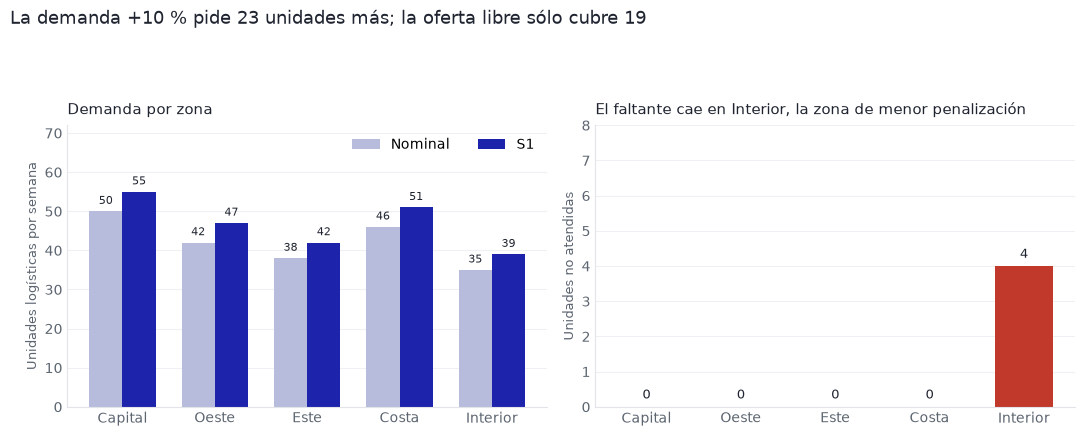

In [16]:
PRIMARY, NOMINAL, ALERT, INK, MUTED, CERO = g.PRIMARY, g.NOMINAL, g.ALERT, g.INK, g.MUTED, g.CERO
etiqueta, limpiar = g.etiqueta, g.limpiar

zonas = list(destinations["destination"])
faltante_s1 = s1.faltantes.set_index("destination")["faltante"]
extra = demanda_s1.sum() - demanda_nominal.sum()
holgura = oferta_nominal.sum() - demanda_nominal.sum()

fig, axes = plt.subplots(1, 2, figsize=(10.8, 4.4))
fig.suptitle(
    f"La demanda +10 % pide {extra:.0f} unidades más; la oferta libre sólo cubre {holgura:.0f}",
    fontsize=13, color=INK, x=0, ha="left",
)
eje = range(len(zonas))
barras_nominal = axes[0].bar(
    [i - 0.18 for i in eje], [demanda_nominal[z] for z in zonas],
    width=0.36, color=NOMINAL, label="Nominal", zorder=2,
)
barras_s1 = axes[0].bar(
    [i + 0.18 for i in eje], [demanda_s1[z] for z in zonas],
    width=0.36, color=PRIMARY, label="S1", zorder=2,
)
axes[0].set_xticks(list(eje), zonas)
axes[0].set_ylim(0, 72)
axes[0].set_ylabel("Unidades logísticas por semana", color=MUTED, fontsize=9)
axes[0].set_title("Demanda por zona", loc="left", color=INK, fontsize=11, pad=8)
for barra in list(barras_nominal) + list(barras_s1):
    axes[0].text(
        barra.get_x() + barra.get_width() / 2, barra.get_height() + 1.2,
        etiqueta(barra.get_height()), ha="center", va="bottom", fontsize=8, color=INK,
    )
axes[0].legend(frameon=False, ncol=2, loc="upper right")
limpiar(axes[0])

faltante = [float(faltante_s1.loc[z]) for z in zonas]
barras = axes[1].bar(
    zonas, faltante, width=0.62, zorder=2,
    color=[ALERT if valor > TOL else CERO for valor in faltante],
)
axes[1].set_ylim(0, 8)
axes[1].set_ylabel("Unidades no atendidas", color=MUTED, fontsize=9)
axes[1].set_title(f"El faltante cae en {faltante_s1.idxmax()}, la zona de menor penalización", loc="left", color=INK, fontsize=11, pad=8)
for barra, valor in zip(barras, faltante):
    axes[1].text(
        barra.get_x() + barra.get_width() / 2, valor + 0.15,
        etiqueta(valor), ha="center", va="bottom", fontsize=9, color=INK,
    )
limpiar(axes[1])
fig.tight_layout(rect=(0, 0, 1, 0.88))
plt.show()

**Lectura.** La demanda sube a 234 unidades y la oferta total es 230: aun usando toda la red, faltan al menos 4. El modelo ubica ese faltante en Interior, la zona con menor penalización (60 puntos por unidad). El costo sube 350 puntos: 240 por el faltante y 110 por transportar 19 unidades más, algunas por rutas más caras.

### Escenario S2 — capacidad Centro–Oeste al 70 %

La capacidad de C-OES pasa a $0{,}70\, u_{C\text{-}OES} = 24{,}5$, sin redondeo. Demanda y oferta quedan igual.

In [17]:
capacidad_s2 = capacidad_nominal.copy()
capacidad_s2.loc["C-OES"] = 0.70 * float(capacidad_nominal.loc["C-OES"])
s2 = resolver(routes, destinations, demanda_nominal, oferta_nominal, capacidad_s2, "S2")
control_s2 = verificar(s2, routes, destinations, demanda_nominal, oferta_nominal, capacidad_s2)
print(f"Capacidad C-OES = {capacidad_s2.loc['C-OES']:.2f} (nominal {capacidad_nominal.loc['C-OES']:.0f})")
informar(s2, control_s2)

Capacidad C-OES = 24.50 (nominal 35)
Estado: OPTIMAL
Costo = 849.50    diferencia vs nominal = +31.50
   transporte = 849.50    penalización = 0.00
Faltante = 0.00    diferencia vs nominal = +0.00
Verificación independiente: cumple


,route_id,origin,destination,capacity,flujo,flujo_nominal,diferencia
0,N-CAP,Norte,Capital,42.0,42.0,42.0,0.0
1,N-OES,Norte,Oeste,28.0,10.5,0.0,10.5
2,N-EST,Norte,Este,30.0,4.0,4.0,0.0
3,N-COS,Norte,Costa,18.0,0.0,0.0,0.0
4,N-INT,Norte,Interior,26.0,0.0,0.0,0.0
5,C-CAP,Centro,Capital,35.0,8.0,8.0,0.0
6,C-OES,Centro,Oeste,24.5,24.5,35.0,-10.5
7,C-EST,Centro,Este,34.0,34.0,34.0,0.0
8,C-COS,Centro,Costa,32.0,8.0,8.0,0.0
9,C-INT,Centro,Interior,28.0,5.0,5.0,0.0


,destination,shortage_penalty,demanda,faltante
0,Capital,80.0,50.0,0.0
1,Oeste,70.0,42.0,0.0
2,Este,65.0,38.0,0.0
3,Costa,75.0,46.0,0.0
4,Interior,60.0,35.0,0.0


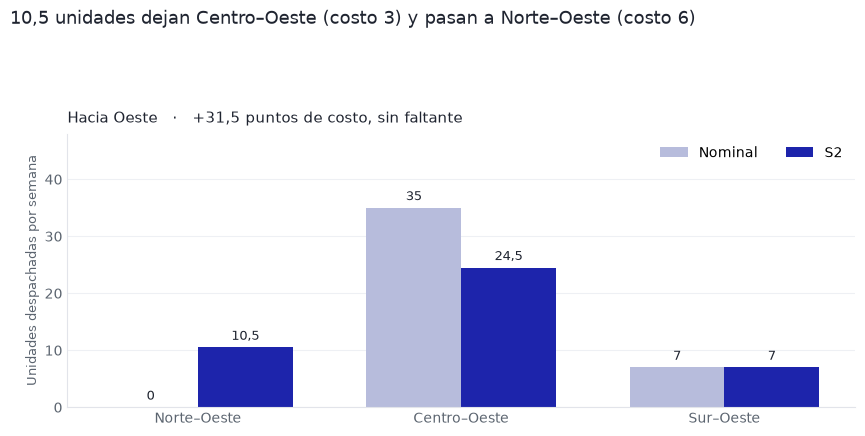

In [18]:
rutas_oeste = ["N-OES", "C-OES", "S-OES"]
nombres = ["Norte–Oeste", "Centro–Oeste", "Sur–Oeste"]
flujo_nominal = nominal.flujos.set_index("route_id").loc[rutas_oeste, "flujo"]
flujo_s2 = s2.flujos.set_index("route_id").loc[rutas_oeste, "flujo"]

fig, ax = plt.subplots(figsize=(8.6, 4.4))
movidas = flujo_nominal.loc["C-OES"] - flujo_s2.loc["C-OES"]
fig.suptitle(
    f"{etiqueta(movidas)} unidades dejan Centro–Oeste (costo 3) y pasan a Norte–Oeste (costo 6)",
    fontsize=13, color=INK, x=0, ha="left",
)
eje = range(len(nombres))
barras_nominal = ax.bar(
    [i - 0.18 for i in eje], flujo_nominal, width=0.36, color=NOMINAL, label="Nominal", zorder=2,
)
barras_s2 = ax.bar(
    [i + 0.18 for i in eje], flujo_s2, width=0.36, color=PRIMARY, label="S2", zorder=2,
)
ax.set_xticks(list(eje), nombres)
ax.set_ylim(0, 48)
ax.set_ylabel("Unidades despachadas por semana", color=MUTED, fontsize=9)
ax.set_title(f"Hacia Oeste   ·   +{etiqueta(s2.objetivo - costo_nominal)} puntos de costo, sin faltante", loc="left", color=INK, fontsize=11, pad=8)
for barra in list(barras_nominal) + list(barras_s2):
    ax.text(
        barra.get_x() + barra.get_width() / 2, barra.get_height() + 0.8,
        etiqueta(barra.get_height()), ha="center", va="bottom", fontsize=9, color=INK,
    )
ax.legend(frameon=False, ncol=2, loc="upper right")
limpiar(ax)
fig.tight_layout(rect=(0, 0, 1, 0.86))
plt.show()

**Lectura.** Al perder 10,5 unidades de capacidad en el corredor más barato hacia Oeste (costo 3), el plan las desvía por Norte–Oeste (costo 6), aprovechando que Norte tenía 14 unidades de oferta ociosa. No aparece faltante y el costo sube exactamente $10{,}5 \times (6-3) = 31{,}5$ puntos, que coincide con el dual $-3$ de la capacidad de C-OES en el caso nominal.

### Escenario S3 — oferta al 90 %

La oferta de cada centro pasa a $0{,}90\, a_i$, sin redondeo. Demanda y capacidades quedan igual.

In [19]:
oferta_s3 = oferta_nominal * 0.90
s3 = resolver(routes, destinations, demanda_nominal, oferta_s3, capacidad_nominal, "S3")
control_s3 = verificar(s3, routes, destinations, demanda_nominal, oferta_s3, capacidad_nominal)
print("Oferta modificada:", {k: round(float(v), 2) for k, v in oferta_s3.items()})
informar(s3, control_s3)

Oferta modificada: {'Norte': 54.0, 'Centro': 85.5, 'Sur': 67.5}
Estado: OPTIMAL
Costo = 1039.50    diferencia vs nominal = +221.50
   transporte = 799.50    penalización = 240.00
Faltante = 4.00    diferencia vs nominal = +4.00
Verificación independiente: cumple


,route_id,origin,destination,capacity,flujo,flujo_nominal,diferencia
0,N-CAP,Norte,Capital,42.0,42.0,42.0,0.0
1,N-OES,Norte,Oeste,28.0,7.0,0.0,7.0
2,N-EST,Norte,Este,30.0,5.0,4.0,1.0
3,N-COS,Norte,Costa,18.0,0.0,0.0,0.0
4,N-INT,Norte,Interior,26.0,0.0,0.0,0.0
5,C-CAP,Centro,Capital,35.0,8.0,8.0,0.0
6,C-OES,Centro,Oeste,35.0,35.0,35.0,0.0
7,C-EST,Centro,Este,34.0,33.0,34.0,-1.0
8,C-COS,Centro,Costa,32.0,8.0,8.0,0.0
9,C-INT,Centro,Interior,28.0,1.5,5.0,-3.5


,destination,shortage_penalty,demanda,faltante
0,Capital,80.0,50.0,0.0
1,Oeste,70.0,42.0,0.0
2,Este,65.0,38.0,0.0
3,Costa,75.0,46.0,0.0
4,Interior,60.0,35.0,4.0


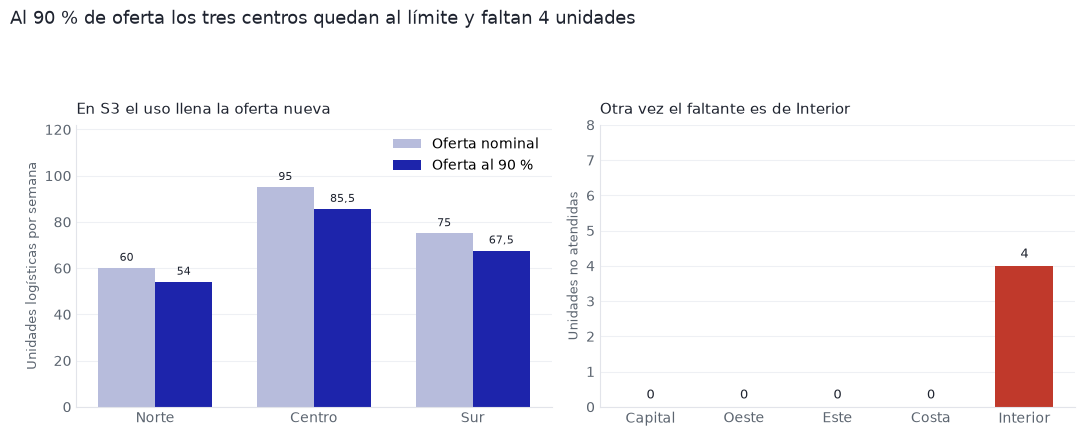

In [20]:
centros = list(origins["origin"])
uso_s3 = s3.flujos.groupby("origin")["flujo"].sum()
faltante_s3 = s3.faltantes.set_index("destination")["faltante"]

fig, axes = plt.subplots(1, 2, figsize=(10.8, 4.4))
fig.suptitle(
    f"Al 90 % de oferta los tres centros quedan al límite y faltan {etiqueta(faltante_s3.sum())} unidades",
    fontsize=13, color=INK, x=0, ha="left",
)
eje = range(len(centros))
barras_nominal = axes[0].bar(
    [i - 0.18 for i in eje], [oferta_nominal[c] for c in centros],
    width=0.36, color=NOMINAL, label="Oferta nominal", zorder=2,
)
barras_s3 = axes[0].bar(
    [i + 0.18 for i in eje], [oferta_s3[c] for c in centros],
    width=0.36, color=PRIMARY, label="Oferta al 90 %", zorder=2,
)
axes[0].set_xticks(list(eje), centros)
axes[0].set_ylim(0, 122)
axes[0].set_ylabel("Unidades logísticas por semana", color=MUTED, fontsize=9)
axes[0].set_title("En S3 el uso llena la oferta nueva", loc="left", color=INK, fontsize=11, pad=8)
for barra in list(barras_nominal) + list(barras_s3):
    axes[0].text(
        barra.get_x() + barra.get_width() / 2, barra.get_height() + 2,
        etiqueta(barra.get_height()), ha="center", va="bottom", fontsize=8, color=INK,
    )
axes[0].legend(frameon=False, loc="upper right")
limpiar(axes[0])

zonas = list(destinations["destination"])
faltante = [float(faltante_s3.loc[z]) for z in zonas]
barras = axes[1].bar(
    zonas, faltante, width=0.62, zorder=2,
    color=[ALERT if valor > TOL else CERO for valor in faltante],
)
axes[1].set_ylim(0, 8)
axes[1].set_ylabel("Unidades no atendidas", color=MUTED, fontsize=9)
axes[1].set_title("Otra vez el faltante es de Interior", loc="left", color=INK, fontsize=11, pad=8)
for barra, valor in zip(barras, faltante):
    axes[1].text(
        barra.get_x() + barra.get_width() / 2, valor + 0.15,
        etiqueta(valor), ha="center", va="bottom", fontsize=9, color=INK,
    )
limpiar(axes[1])
fig.tight_layout(rect=(0, 0, 1, 0.88))
plt.show()

**Lectura.** La oferta total baja a 207 unidades frente a 211 de demanda: el faltante mínimo es 4 y vuelve a caer en Interior. El costo sube 221,5 puntos: la penalización agrega 240 y el transporte baja 18,5 porque se despachan 4 unidades menos. S1 y S3 muestran que la red no tiene margen de oferta: con 230 unidades disponibles frente a 211 pedidas, la holgura es de 19 unidades: un aumento de la demanda total de más del 9 % o una caída de la oferta total de más del 8 % ya produce faltante.

### Los tres escenarios en un gráfico

Costo óptimo de cada escenario frente al nominal, separado en transporte y penalización por faltante. Las cuatro instancias usan la misma formulación y la misma verificación; sólo cambia el grupo de datos indicado debajo de cada barra.

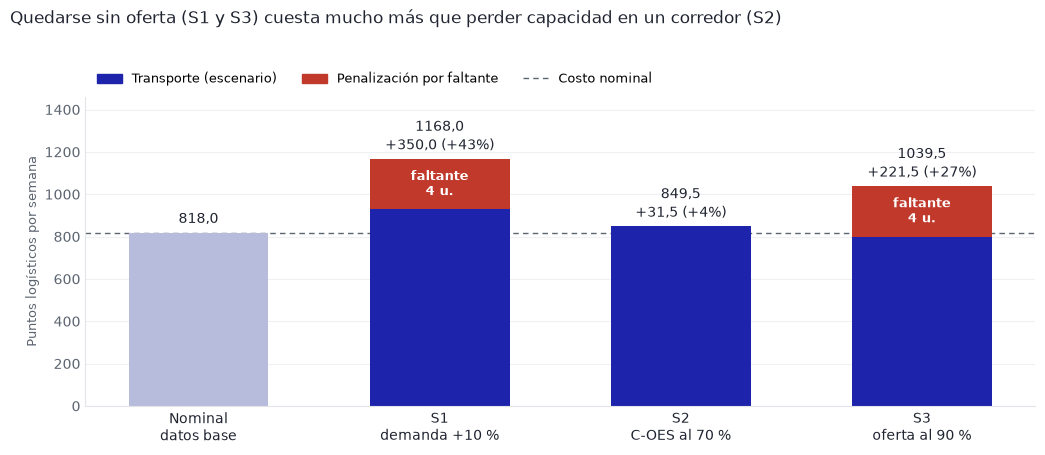

In [21]:
escenarios = [
    ("Nominal", "datos base", nominal, control_nominal),
    ("S1", "demanda +10 %", s1, control_s1),
    ("S2", "C-OES al 70 %", s2, control_s2),
    ("S3", "oferta al 90 %", s3, control_s3),
]
fig, ax = plt.subplots(figsize=(10.4, 4.6))
pos = np.arange(len(escenarios))
transporte = np.array([c["transporte"] for *_, c in escenarios])
penalizacion = np.array([c["penalizacion"] for *_, c in escenarios])
costos = transporte + penalizacion
colores_transporte = [g.NOMINAL] + [g.PRIMARY] * (len(escenarios) - 1)
ax.bar(pos, transporte, width=0.58, color=colores_transporte, zorder=2)
ax.bar(pos, penalizacion, bottom=transporte, width=0.58, color=g.ALERT, zorder=2)
ax.axhline(costo_nominal, color=g.MUTED, lw=1, ls=(0, (4, 3)), zorder=1)

for x_, (nombre, _, sol, control), costo in zip(pos, escenarios, costos):
    texto = f"{costo:.1f}".replace(".", ",")
    if nombre != "Nominal":
        delta = costo - costo_nominal
        texto += f"\n{delta:+.1f} ({delta / costo_nominal:+.0%})".replace(".", ",")
    ax.text(x_, costo + 25, texto, ha="center", va="bottom", fontsize=10, color=g.INK, linespacing=1.3)
    falta = float(sol.faltantes["faltante"].sum())
    if falta > TOL:
        ax.text(x_, transporte[x_] + penalizacion[x_] / 2, f"faltante\n{falta:.0f} u.", ha="center", va="center",
                fontsize=9, color="white", fontweight="bold")

ax.set_xticks(pos, [f"{n}\n{d}" for n, d, *_ in escenarios])
ax.set_ylim(0, costos.max() * 1.25)
ax.set_ylabel("Puntos logísticos por semana", color=g.MUTED, fontsize=9)
g.limpiar(ax)
ax.tick_params(axis="x", colors=g.INK, labelsize=10)
handles = [plt.Rectangle((0, 0), 1, 1, color=g.PRIMARY), plt.Rectangle((0, 0), 1, 1, color=g.ALERT),
           plt.Line2D([], [], color=g.MUTED, lw=1, ls=(0, (4, 3)))]
ax.legend(handles, ["Transporte (escenario)", "Penalización por faltante", "Costo nominal"], frameon=False, ncol=3,
          loc="lower left", bbox_to_anchor=(0, 1.0), fontsize=9)

con_faltante = [n for n, _, sol, _ in escenarios if sol.faltantes["faltante"].sum() > TOL]
fig.suptitle(f"Quedarse sin oferta ({' y '.join(con_faltante)}) cuesta mucho más que perder capacidad en un corredor (S2)",
             fontsize=12.5, color=g.INK, x=0, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

**Lectura.** S1 y S3 terminan con 4 unidades de faltante, y la penalización (240 puntos) explica la mayor parte de su aumento de costo: +43 % y +27 %. S2 pierde capacidad en el corredor más barato hacia Oeste, pero la red la reemplaza con oferta ociosa de Norte: sube sólo el transporte (+4 %) y no hay faltante. La red tolera mejor perder un corredor que perder oferta o enfrentar más demanda.

## Plan de resguardo

Se resuelve el mismo modelo con una demanda de diseño cinco por ciento mayor, redondeada hacia arriba: $d_j^{res}=\lceil 1{,}05\, d_j\rceil$, con oferta y capacidades nominales. Este plan **no** es un cuarto escenario de control: es una política alternativa que queda fija y se compara, en la Parte II, contra el plan nominal sobre los mismos futuros.

In [22]:
demanda_resguardo = techo(1.05, demanda_nominal)
resguardo = resolver(routes, destinations, demanda_resguardo, oferta_nominal, capacidad_nominal, "Resguardo")
control_resguardo = verificar(resguardo, routes, destinations, demanda_resguardo, oferta_nominal, capacidad_nominal)
print("Demanda de diseño:", demanda_resguardo.to_dict())
informar(resguardo, control_resguardo)

Demanda de diseño: {'Capital': 53.0, 'Oeste': 45.0, 'Este': 40.0, 'Costa': 49.0, 'Interior': 37.0}
Estado: OPTIMAL
Costo = 892.00    diferencia vs nominal = +74.00
   transporte = 892.00    penalización = 0.00
Faltante = 0.00    diferencia vs nominal = +0.00
Verificación independiente: cumple


,route_id,origin,destination,capacity,flujo,flujo_nominal,diferencia
0,N-CAP,Norte,Capital,42.0,42.0,42.0,0.0
1,N-OES,Norte,Oeste,28.0,3.0,0.0,3.0
2,N-EST,Norte,Este,30.0,9.0,4.0,5.0
3,N-COS,Norte,Costa,18.0,0.0,0.0,0.0
4,N-INT,Norte,Interior,26.0,0.0,0.0,0.0
5,C-CAP,Centro,Capital,35.0,11.0,8.0,3.0
6,C-OES,Centro,Oeste,35.0,35.0,35.0,0.0
7,C-EST,Centro,Este,34.0,31.0,34.0,-3.0
8,C-COS,Centro,Costa,32.0,11.0,8.0,3.0
9,C-INT,Centro,Interior,28.0,7.0,5.0,2.0


,destination,shortage_penalty,demanda,faltante
0,Capital,80.0,53.0,0.0
1,Oeste,70.0,45.0,0.0
2,Este,65.0,40.0,0.0
3,Costa,75.0,49.0,0.0
4,Interior,60.0,37.0,0.0


In [23]:
def flujo(x):
    return f"{round(x, 4) + 0.0:g}".replace(".", ",")

def diferencia(x):
    return f"{round(x, 4) + 0.0:+g}".replace(".", ",").replace("-", "−")

cambios = comparar_flujos(resguardo, nominal)
cambios = cambios.loc[cambios["diferencia"].abs() > TOL]
ruta_cambios = OUTPUTS_DIR / "presentacion" / "rutas_nominal_resguardo_oscuro.png"
g.tabla_imagen(
    ruta_cambios,
    "Rutas cuyo flujo cambia entre el plan nominal y el de resguardo",
    ["Ruta", "Capacidad\n(u./semana)", "Nominal\n(u./semana)", "Resguardo\n(u./semana)", "Diferencia\n(u./semana)"],
    [[f"{r.route_id}  ({r.origin} → {r.destination})", flujo(r.capacity), flujo(r.flujo_nominal), flujo(r.flujo),
      diferencia(r.diferencia)] for r in cambios.itertuples()]
    + [["Despacho total", "—", flujo(nominal.flujos["flujo"].sum()), flujo(resguardo.flujos["flujo"].sum()),
        diferencia(resguardo.flujos["flujo"].sum() - nominal.flujos["flujo"].sum())]],
    nota=f"Las otras {len(routes) - len(cambios)} rutas llevan el mismo flujo en ambos planes. "
         f"Costo planificado: {nominal.objetivo:g} y {resguardo.objetivo:g} puntos.",
    ancho=9.5, x_valores=0.55, destacada=4,
)
print("Versión en tema oscuro para el informe:", ruta_cambios.relative_to(ROOT))

Versión en tema oscuro para el informe: outputs/presentacion/rutas_nominal_resguardo_oscuro.png


**Lectura.** El resguardo despacha 224 unidades por semana, 13 más que el nominal, sin faltante respecto de su demanda de diseño y con 74 puntos más de costo planificado. Suben N-OES, N-EST, C-CAP, C-COS y C-INT, que tenían holgura, y C-EST baja 3 unidades. Frente a la demanda nominal, esas 13 unidades no se necesitan; su valor sólo aparece si la demanda real supera la nominal o si fallan rutas, que es lo que evalúa la Parte II.

## Comparación consolidada

Las cinco instancias resueltas con la misma función y verificadas con la misma tolerancia. *Despacho planificado* es la suma de los flujos $\sum x_{ij}$.

In [24]:
instancias = [
    ("Nominal", nominal, control_nominal, "Plan de referencia: cubre toda la demanda; Sur agota su oferta."),
    ("S1: demanda +10 %", s1, control_s1, "La oferta total no alcanza: 4 unidades faltan en Interior."),
    ("S2: C-OES al 70 %", s2, control_s2, "Se desvían 10,5 unidades a Norte–Oeste; sin faltante."),
    ("S3: oferta al 90 %", s3, control_s3, "La oferta no alcanza: 4 unidades faltan en Interior."),
    ("Resguardo: demanda +5 %", resguardo, control_resguardo, "Política alternativa para la Parte II: 13 unidades más por semana."),
]
resumen_p1 = pd.DataFrame([
    {
        "instancia": nombre,
        "estado": sol.estado,
        "costo": sol.objetivo,
        "diferencia_vs_nominal": sol.objetivo - costo_nominal,
        "transporte": control["transporte"],
        "penalizacion": control["penalizacion"],
        "faltante": float(sol.faltantes["faltante"].sum()),
        "despacho_planificado": float(sol.flujos["flujo"].sum()),
        "verificacion": "cumple" if control["controles"]["cumple"].all() else "NO cumple",
        "lectura": lectura,
    }
    for nombre, sol, control, lectura in instancias
])
assert (resumen_p1["estado"] == "OPTIMAL").all() and (resumen_p1["verificacion"] == "cumple").all()
resumen_p1.round(2)

,instancia,estado,costo,diferencia_vs_nominal,transporte,penalizacion,faltante,despacho_planificado,verificacion,lectura
0,Nominal,OPTIMAL,818.0,0.0,818.0,0.0,0.0,211.0,cumple,Plan de referencia: cubre toda la demanda; Sur...
1,S1: demanda +10 %,OPTIMAL,1168.0,350.0,928.0,240.0,4.0,230.0,cumple,La oferta total no alcanza: 4 unidades faltan ...
2,S2: C-OES al 70 %,OPTIMAL,849.5,31.5,849.5,0.0,0.0,211.0,cumple,"Se desvían 10,5 unidades a Norte–Oeste; sin fa..."
3,S3: oferta al 90 %,OPTIMAL,1039.5,221.5,799.5,240.0,4.0,207.0,cumple,La oferta no alcanza: 4 unidades faltan en Int...
4,Resguardo: demanda +5 %,OPTIMAL,892.0,74.0,892.0,0.0,0.0,224.0,cumple,Política alternativa para la Parte II: 13 unid...


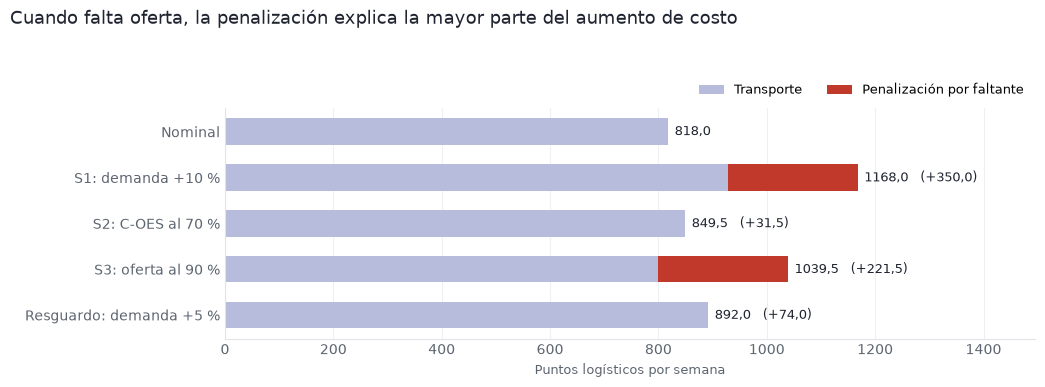

In [25]:
fig, ax = plt.subplots(figsize=(10.4, 3.9))
orden = resumen_p1.iloc[::-1]
pos = range(len(orden))
ax.barh(pos, orden["transporte"], color=g.NOMINAL, height=0.58, label="Transporte", zorder=2)
ax.barh(pos, orden["penalizacion"], left=orden["transporte"], color=g.ALERT, height=0.58, label="Penalización por faltante", zorder=2)
for y, (_, fila) in zip(pos, orden.iterrows()):
    texto = f"{fila['costo']:.1f}".replace(".", ",")
    if abs(fila["diferencia_vs_nominal"]) > TOL:
        texto += f"   ({fila['diferencia_vs_nominal']:+.1f})".replace(".", ",")
    ax.text(fila["costo"] + 12, y, texto, va="center", fontsize=9.5, color=g.INK)
ax.set_yticks(list(pos), orden["instancia"])
ax.set_xlim(0, resumen_p1["costo"].max() * 1.28)
ax.set_xlabel("Puntos logísticos por semana", color=g.MUTED, fontsize=9)
ax.xaxis.grid(True, color=g.GRID)
ax.yaxis.grid(False)
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
ax.spines["left"].set_color(g.SPINE)
ax.spines["bottom"].set_color(g.SPINE)
ax.tick_params(length=0, colors=g.MUTED, labelsize=10)
ax.set_axisbelow(True)
ax.legend(frameon=False, ncol=2, loc="lower right", bbox_to_anchor=(1.0, 1.0), fontsize=9)
fig.suptitle("Cuando falta oferta, la penalización explica la mayor parte del aumento de costo",
             fontsize=13, color=g.INK, x=0, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

## Archivos puente para la Parte II

La Parte II lee estas dos tablas directamente; no se copian flujos a mano ni se reoptimiza. Cada archivo tiene una fila por ruta, en el orden de `routes.csv`, con `route_id`, `origin`, `destination`, `planned_flow` (unidades por semana), `capacity`, `unit_cost` y `policy`.

GLOP devuelve ruido de punto flotante (por ejemplo `3.999999999999998` o `4e-15`); `planned_flow` se redondea a 9 decimales, muy por debajo de la tolerancia de $10^{-7}$, para que el archivo se serialice siempre igual. Antes y después de escribir, `validar_politica` comprueba esquema, rutas, metadatos, no negatividad, capacidades y ofertas.

Las huellas SHA-256 quedan en `outputs/part1_manifest.json`; la Parte II las recalcula y se detiene si un archivo fue alterado.

In [26]:
OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)
ruta_nominal = OUTPUTS_DIR / "part1_solution.csv"
ruta_resguardo = OUTPUTS_DIR / "part1_solution_buffer.csv"
hash_nominal = exportar_politica(nominal, "nominal", ruta_nominal, routes, origins)
hash_resguardo = exportar_politica(resguardo, "resguardo", ruta_resguardo, routes, origins)

manifiesto = {
    "generado_por": "notebooks/part1_primal.ipynb",
    "solver": "OR-Tools GLOP",
    "tolerancia": TOL,
    "entradas": {f"data/{n}": sha256(DATA_DIR / n) for n in ("origins.csv", "destinations.csv", "routes.csv")},
    "politicas": {
        "nominal": {
            "archivo": "outputs/part1_solution.csv", "sha256": hash_nominal,
            "objetivo": nominal.objetivo, "costo_transporte": control_nominal["transporte"],
            "faltante": faltante_nominal, "despacho": float(nominal.flujos["flujo"].sum()),
        },
        "resguardo": {
            "archivo": "outputs/part1_solution_buffer.csv", "sha256": hash_resguardo,
            "objetivo": resguardo.objetivo, "costo_transporte": control_resguardo["transporte"],
            "faltante": float(resguardo.faltantes["faltante"].sum()),
            "despacho": float(resguardo.flujos["flujo"].sum()),
        },
    },
    "escenarios": {fila["instancia"]: fila["costo"] for _, fila in resumen_p1.iterrows()},
}
(OUTPUTS_DIR / "part1_manifest.json").write_text(json.dumps(manifiesto, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")

print(f"part1_solution.csv         SHA-256 {hash_nominal}")
print(f"part1_solution_buffer.csv  SHA-256 {hash_resguardo}")
puente = pd.read_csv(ruta_nominal).merge(
    pd.read_csv(ruta_resguardo)[["route_id", "planned_flow"]], on="route_id", suffixes=("_nominal", "_resguardo")
)
puente.drop(columns="policy")

part1_solution.csv         SHA-256 0be31847150b8bfeb414218f7b74371fb4b0c0c0ede8be9fab7170ec3254d279
part1_solution_buffer.csv  SHA-256 bf2977090a26707bf15674d19f3912e0cc0c5b6ab48adfb6be3b8158bc2c2267


,route_id,origin,destination,planned_flow_nominal,capacity,unit_cost,planned_flow_resguardo
0,N-CAP,Norte,Capital,42.0,42.0,4.0,42.0
1,N-OES,Norte,Oeste,0.0,28.0,6.0,3.0
2,N-EST,Norte,Este,4.0,30.0,5.0,9.0
3,N-COS,Norte,Costa,0.0,18.0,9.0,0.0
4,N-INT,Norte,Interior,0.0,26.0,7.0,0.0
5,C-CAP,Centro,Capital,8.0,35.0,5.0,11.0
6,C-OES,Centro,Oeste,35.0,35.0,3.0,35.0
7,C-EST,Centro,Este,34.0,34.0,4.0,31.0
8,C-COS,Centro,Costa,8.0,32.0,6.0,11.0
9,C-INT,Centro,Interior,5.0,28.0,5.0,7.0


## Conclusiones de la Parte I

- **Plan nominal.** Con la oferta reconstruida, el mínimo costo para cubrir la semana típica es 818 puntos, sin faltante. El plan es óptimo (brecha dual nula y holgura complementaria) y cumple todas las cotas recalculadas de forma independiente. No es único: hay óptimos alternativos del mismo costo.
- **Fragilidad.** La red sólo tiene 19 unidades de oferta libre por semana. Un aumento del 10 % en la demanda (S1) o una caída del 10 % en la oferta (S3) generan 4 unidades de faltante y elevan el costo entre 27 % y 43 %. Una reducción fuerte en un corredor (S2) se absorbe con un desvío más caro, sin faltante.
- **Resguardo.** El plan con demanda de diseño +5 % cuesta 74 puntos más por semana (+9 %) y despacha 13 unidades más. Optimizar con datos nominales no dice cuál de los dos planes conviene cuando la demanda y las rutas son inciertas: eso lo responde la Parte II con estos dos archivos fijos.

## Fuentes

Formulación de un problema de transporte como programa lineal:

[Transportation Problem - LP Formulation](https://www.youtube.com/watch?v=WZIyL6pcItY), Joshua Emmanuel.

Documentación del solver: [OR-Tools — Linear optimization (GLOP)](https://developers.google.com/optimization/lp/lp_example).